In [1]:
%pip install "tensorflow-hub<0.17" pillow matplotlib

Could not fetch URL https://pypi.org/simple/tensorflow/: There was a problem confirming the ssl certificate: HTTPSConnectionPool(host='pypi.org', port=443): Max retries exceeded with url: /simple/tensorflow/ (Caused by SSLError(SSLError("bad handshake: Error([('SSL routines', 'tls_process_server_certificate', 'certificate verify failed')])"))) - skipping
ERROR: Could not find a version that satisfies the requirement tensorflow<2.16,>=2.15 (from tf-keras>=2.14.1->tensorflow-hub<0.17) (from versions: none)
ERROR: No matching distribution found for tensorflow<2.16,>=2.15 (from tf-keras>=2.14.1->tensorflow-hub<0.17)
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Step 1: Import libraries

import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

print("Libraries imported successfully!")

/home/user/anaconda3/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Libraries imported successfully!


In [3]:
# Step 2: Load pretrained model

print("Loading pretrained model...")

model_url = "https://tfhub.dev/tensorflow/efficientdet/lite0/detection/1"
detector = hub.load(model_url)

detect_fn = detector.signatures["serving_default"]

print("Pretrained model loaded successfully!")

Loading pretrained model...
Pretrained model loaded successfully!


In [4]:
# Step 3: Load the image

image_path = "/home/user/Downloads/cat.jpeg"

if not os.path.exists(image_path):
    raise FileNotFoundError("Image not found: " + image_path)

image = Image.open(image_path).convert("RGB")
image = image.resize((512, 512))

image_array = np.array(image, dtype=np.uint8)

print("Dog image loaded successfully!")

Dog image loaded successfully!


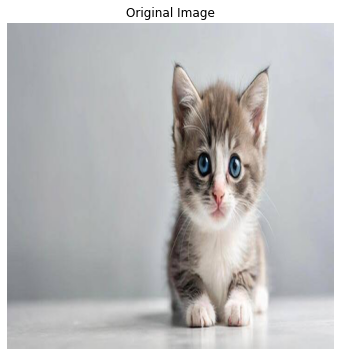

In [5]:
# Step 4: Display original image

plt.figure(figsize=(6, 6))
plt.imshow(image_array)
plt.title("Original Image")
plt.axis("off")
plt.show()


In [6]:
# Step 5: Prepare image for detection

input_tensor = tf.convert_to_tensor(
    image_array,
    dtype=tf.uint8
)

input_tensor = tf.expand_dims(input_tensor, axis=0)

In [7]:
# Step 6: Perform object detection

print("Detecting objects...")

result = detect_fn(input_tensor)

print("Object detection completed!")

Detecting objects...
Object detection completed!


In [8]:
# Step 7: Extract model outputs
# output_0 = bounding boxes
# output_1 = confidence scores
# output_2 = class IDs
# output_3 = number of detections

boxes = result["output_0"][0].numpy()
scores = result["output_1"][0].numpy()
classes = result["output_2"][0].numpy()
num_detections = int(result["output_3"][0].numpy())

print("Detection results extracted successfully!")

Detection results extracted successfully!


Object: 1 | Class ID: 17 | Confidence: 0.851


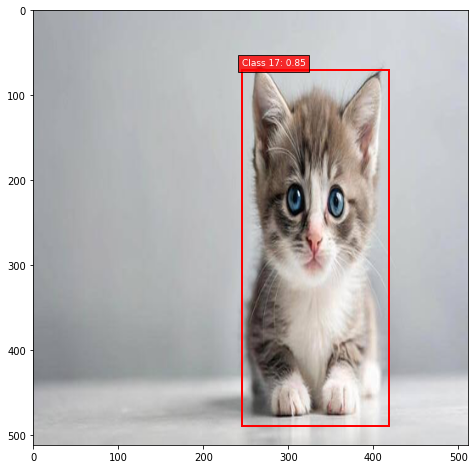

In [9]:

# Step 8: Draw bounding boxes

height, width, _ = image_array.shape

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image_array)

detected_count = 0

# Display only detections with confidence >= 30%
for i in range(min(num_detections, len(scores))):

    score = float(scores[i])

    if score < 0.30:
        continue

    # Model coordinates are in pixel units.
    # Clip them to the image boundaries.
    ymin, xmin, ymax, xmax = boxes[i]

    left = max(0, min(int(xmin), width - 1))
    top = max(0, min(int(ymin), height - 1))
    right = max(0, min(int(xmax), width))
    bottom = max(0, min(int(ymax), height))

    # Skip invalid boxes
    if right <= left or bottom <= top:
        continue

    # Draw rectangle
    rectangle = plt.Rectangle(
        (left, top),
        right - left,
        bottom - top,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    ax.add_patch(rectangle)

    # Display class ID and confidence
    class_id = int(classes[i])

    label = "Class {}: {:.2f}".format(class_id, score)

    ax.text(
        left,
        max(top - 5, 0),
        label,
        color="white",
        fontsize=9,
        bbox=dict(facecolor="red", alpha=0.8)
    )

    detected_count += 1

    print(
        "Object:", detected_count,
        "| Class ID:", class_id,
        "| Confidence:", round(score, 3)
    )



In [10]:
#Step 9: Display final output

ax.set_title("Object Detection Using EfficientDet-Lite0")
ax.axis("off")
plt.tight_layout()
plt.show()

print("\nTotal objects detected:", detected_count)

if detected_count == 0:
    print("No objects detected above the confidence threshold.")


# Step 10: Conclusion

print("\nCONCLUSION:")
print(
    "Object detection was implemented using the pretrained "
    "EfficientDet-Lite0 CNN model. Bounding boxes and confidence "
    "scores were displayed for detected objects."
)

<Figure size 432x288 with 0 Axes>


Total objects detected: 1

CONCLUSION:
Object detection was implemented using the pretrained EfficientDet-Lite0 CNN model. Bounding boxes and confidence scores were displayed for detected objects.
